# Baseline: EfficientNet-B4 trained FROM SCRATCH (no pretrained weights) on P2datasetFull

**Purpose:** the same EfficientNet-B4 architecture as the pretrained baseline, but with **random initial weights** (`weights=None`),
so it follows the same rule as the main model: **no pretrained weights**. This shows whether a large standard CNN, trained only on
P2datasetFull, does better or worse than the custom SE-ResNet CNN + Transformer.

- Same data and settings as the main model: P2datasetFull `train` / `val1` / `test1`, 224 x 224, batch 32, same augmentation,
  AdamW (lr 0.001, weight decay 0.0001), up to 30 epochs, early stopping on val ROC-AUC (patience 6), learning-rate halving.
- All layers are trained from the start (there is nothing pretrained to freeze).
- `test1` is used **only once**, at the end.
- Results are saved to `ML-dataset/P2_results/efficientnet_b4_scratch/` (main model and pretrained baseline are **not overwritten**).
- This notebook does **not** display any dataset images.

**Before running:** Runtime -> Change runtime type -> **T4 GPU** -> Save. Then Runtime -> Run all.
Expected time on a T4: about 45-90 minutes (about 2 minutes per epoch, up to 30 epochs).

In [1]:
# Cell 0: mount Google Drive and set configuration
from google.colab import drive
drive.mount("/content/drive")
from pathlib import Path
import os, glob

# Find P2datasetFull (works with the ML-dataset folder in My Drive or as a shortcut to a shared folder)
candidates = ([Path("/content/drive/MyDrive/ML-dataset/P2datasetFull")] +
              [Path(p) for p in glob.glob("/content/drive/.shortcut-targets-by-id/*/ML-dataset/P2datasetFull")])
DATASET_DIR = next((p for p in candidates if p.is_dir()), None)
assert DATASET_DIR, ("P2datasetFull not found. In Google Drive: Shared with me -> right-click ML-dataset -> "
                     "Organize -> Add shortcut -> My Drive, then run this cell again.")
SPLITS = ["train", "val1", "test1"]
CLASS_MAP = {"1": "real", "2": "fake"}      # same mapping as the main CNN-Transformer notebook
LOCAL_ROOT = Path("/content/p2dataset_images")
RESULTS_DIR = DATASET_DIR.parent / "P2_results" / "efficientnet_b4_scratch"   # separate folder: main results stay untouched
RESULTS_DIR.mkdir(parents=True, exist_ok=True)
for split in SPLITS:
    for folder in CLASS_MAP:
        assert (DATASET_DIR / split / folder).is_dir(), f"Missing folder {DATASET_DIR / split / folder}"
print("Dataset:", DATASET_DIR)
print("Results:", RESULTS_DIR)

Mounted at /content/drive
Dataset: /content/drive/MyDrive/ML-dataset/P2datasetFull
Results: /content/drive/MyDrive/ML-dataset/P2_results/efficientnet_b4_scratch


In [2]:
# Cell 1: copy images to local disk (much faster than reading from Drive) and check every file
import shutil
from PIL import Image
from collections import Counter
from concurrent.futures import ThreadPoolExecutor

VALID_EXT = {".jpg", ".jpeg", ".png", ".bmp"}
shutil.rmtree(LOCAL_ROOT, ignore_errors=True)

def process(task):
    src, dst_dir, idx = task
    try:
        with Image.open(src) as im:
            im.verify()
        with Image.open(src) as im:
            fmt, mode = im.format, im.mode
            if fmt in ("JPEG", "BMP", "PNG") and mode in ("RGB", "L"):
                ext = {"JPEG": ".jpg", "BMP": ".bmp", "PNG": ".png"}[fmt]
                shutil.copyfile(src, dst_dir / f"{idx:06d}{ext}")
                return "copied", src
            im.convert("RGB").save(dst_dir / f"{idx:06d}.jpg", quality=95)
            return "converted", src
    except Exception as e:
        return "skipped", f"{src} ({type(e).__name__})"

for split in SPLITS:
    for folder, class_name in CLASS_MAP.items():
        src_dir = DATASET_DIR / split / folder
        dst_dir = LOCAL_ROOT / split / class_name
        dst_dir.mkdir(parents=True, exist_ok=True)
        files = sorted(f for f in src_dir.iterdir() if f.suffix.lower() in VALID_EXT)
        with ThreadPoolExecutor(max_workers=16) as pool:
            results = list(pool.map(process, [(f, dst_dir, i) for i, f in enumerate(files)]))
        print(f"{split:6s} {class_name:5s} (folder {folder}): {dict(Counter(s for s, _ in results))}")
data_root = str(LOCAL_ROOT)

train  real  (folder 1): {'copied': 3207}
train  fake  (folder 2): {'copied': 3050}
val1   real  (folder 1): {'copied': 3150}
val1   fake  (folder 2): {'copied': 3071}
test1  real  (folder 1): {'copied': 3171}
test1  fake  (folder 2): {'copied': 3075}


In [3]:
# Cell 2: check every image with TensorFlow's decoder; repair or remove bad files (same as the main notebook)
import tensorflow as tf
from PIL import ImageFile
ImageFile.LOAD_TRUNCATED_IMAGES = True

def tf_ok(p):
    try:
        tf.io.decode_image(tf.io.read_file(str(p)), channels=3, expand_animations=False)
        return True
    except Exception:
        return False

fixed, removed = [], []
for path in sorted(p for p in LOCAL_ROOT.rglob("*") if p.is_file()):
    if tf_ok(path):
        continue
    new_path = path.with_suffix(".jpg")
    try:
        with Image.open(path) as im:
            rgb = im.convert("RGB")
        rgb.save(new_path, quality=95)
        if new_path != path:
            path.unlink()
        if tf_ok(new_path):
            fixed.append(str(path)); continue
    except Exception:
        pass
    for p in {path, new_path}:
        p.unlink(missing_ok=True)
    removed.append(str(path))
print(f"Repaired: {len(fixed)}  Removed: {len(removed)}")

Repaired: 3  Removed: 0


In [4]:
# Cell 3: GPU check + load the three splits (224 x 224, batch 32, same as the main model)
print("GPU:", tf.config.list_physical_devices("GPU"))
assert tf.config.list_physical_devices("GPU"), "No GPU. Runtime -> Change runtime type -> T4 GPU, then Run all again."
tf.keras.mixed_precision.set_global_policy("mixed_float16")   # faster on T4; the output layer stays float32

IMG_SIZE = (224, 224); BATCH_SIZE = 32; SEED = 42
def load_split(split):
    return tf.keras.utils.image_dataset_from_directory(
        os.path.join(data_root, split), class_names=["real", "fake"], label_mode="binary",
        image_size=IMG_SIZE, batch_size=BATCH_SIZE, shuffle=(split == "train"), seed=SEED)
train_ds = load_split("train").prefetch(tf.data.AUTOTUNE)
val_ds = load_split("val1").prefetch(tf.data.AUTOTUNE)
test_ds = load_split("test1").prefetch(tf.data.AUTOTUNE)
print("Class index 0 = real (non-pornographic); class index 1 = fake (pornographic)")

GPU: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]
Found 6257 files belonging to 2 classes.
Found 6221 files belonging to 2 classes.
Found 6246 files belonging to 2 classes.
Class index 0 = real (non-pornographic); class index 1 = fake (pornographic)


In [5]:
# Cell 4: build EfficientNet-B4 with RANDOM weights (weights=None = no pretraining) + binary head
from tensorflow.keras import layers, Model
import numpy as np

inputs = tf.keras.Input(shape=(*IMG_SIZE, 3), name="image")
aug = tf.keras.Sequential([layers.RandomFlip("horizontal"), layers.RandomRotation(0.05),
                           layers.RandomZoom(0.1), layers.RandomContrast(0.15)], name="augmentation")  # same as main model
x = aug(inputs)
base = tf.keras.applications.EfficientNetB4(include_top=False, weights=None, input_shape=(*IMG_SIZE, 3))
# weights=None -> every layer starts from random values; nothing is downloaded from ImageNet.
# The model's built-in input normalization still expects raw 0-255 pixels, so no Rescaling layer here.
base.trainable = True
x = base(x)
x = layers.GlobalAveragePooling2D(name="gap")(x)
x = layers.Dropout(0.35)(x)
outputs = layers.Dense(1, activation="sigmoid", dtype="float32", name="fake_probability")(x)
model = Model(inputs, outputs, name="efficientnet_b4_scratch")

METRICS = [tf.keras.metrics.BinaryAccuracy(name="accuracy"), tf.keras.metrics.AUC(name="auc"),
           tf.keras.metrics.Precision(name="precision"), tf.keras.metrics.Recall(name="recall")]
n_params = sum(int(tf.size(w)) for w in model.trainable_weights)
print(f"Trainable parameters: {n_params:,} (all random at start - no pretrained weights)")

Trainable parameters: 17,550,409 (all random at start - no pretrained weights)


In [6]:
# Cell 5: train from scratch (same optimizer, epochs and callbacks as the main model)
import time
model.compile(optimizer=tf.keras.optimizers.AdamW(learning_rate=1e-3, weight_decay=1e-4),
              loss="binary_crossentropy", metrics=METRICS)
ckpt = RESULTS_DIR / "efficientnet_b4_scratch.keras"
callbacks = [tf.keras.callbacks.EarlyStopping(monitor="val_auc", mode="max", patience=6, restore_best_weights=True),
             tf.keras.callbacks.ReduceLROnPlateau(monitor="val_auc", mode="max", factor=0.5, patience=2, min_lr=1e-5),
             tf.keras.callbacks.ModelCheckpoint(str(ckpt), monitor="val_auc", mode="max", save_best_only=True)]
t0 = time.time()
hist = model.fit(train_ds, validation_data=val_ds, epochs=30, callbacks=callbacks)
print(f"Training done in {(time.time() - t0) / 60:.1f} min | best model saved to {ckpt}")

Epoch 1/30
196/196 ━━━━━━━━━━━━━━━━━━━━ 325s 1s/step - accuracy: 0.7090 - auc: 0.7775 - loss: 0.5824 - precision: 0.6925 - recall: 0.7249 - val_accuracy: 0.4937 - val_auc: 0.5380 - val_loss: 1.6733 - val_precision: 0.4937 - val_recall: 1.0000 - learning_rate: 0.0010
Epoch 2/30
196/196 ━━━━━━━━━━━━━━━━━━━━ 189s 967ms/step - accuracy: 0.7999 - auc: 0.8697 - loss: 0.4658 - precision: 0.7969 - recall: 0.7911 - val_accuracy: 0.7877 - val_auc: 0.8548 - val_loss: 0.4820 - val_precision: 0.8358 - val_recall: 0.7092 - learning_rate: 0.0010
Epoch 3/30
196/196 ━━━━━━━━━━━━━━━━━━━━ 189s 964ms/step - accuracy: 0.8407 - auc: 0.9124 - loss: 0.3801 - precision: 0.8371 - recall: 0.8357 - val_accuracy: 0.8298 - val_auc: 0.9121 - val_loss: 0.4344 - val_precision: 0.8069 - val_recall: 0.8613 - learning_rate: 0.0010
Epoch 4/30
196/196 ━━━━━━━━━━━━━━━━━━━━ 172s 878ms/step - accuracy: 0.8477 - auc: 0.9220 - loss: 0.3563 - precision: 0.8368 - recall: 0.8541 - val_accuracy: 0.6960 - val_auc: 0.8388 - val_loss:

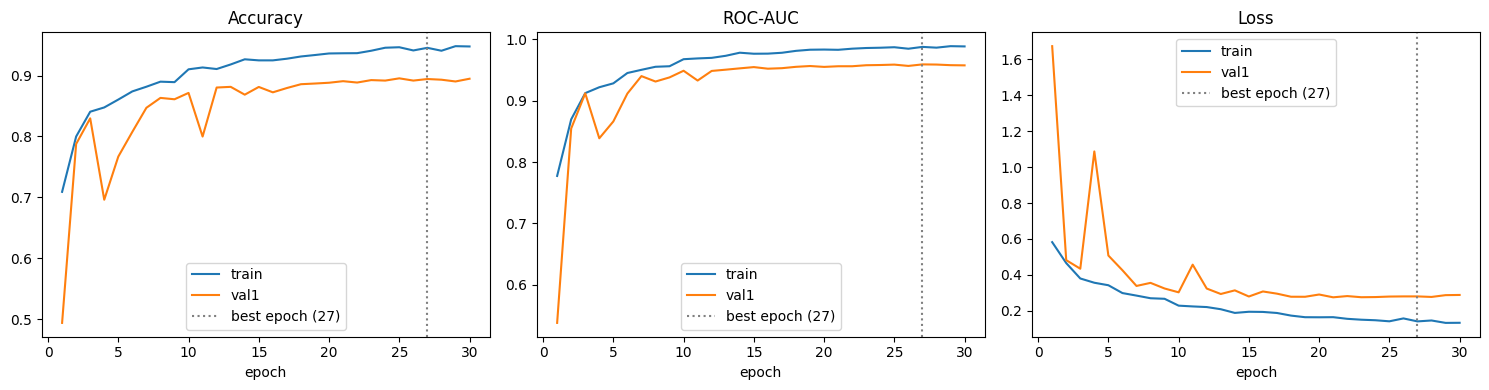

Epochs run: 30 | best epoch: 27 | best val ROC-AUC: 95.9%


In [7]:
# Cell 6: learning curves
import matplotlib.pyplot as plt
h = hist.history; ep = np.arange(1, len(h["loss"]) + 1)
best_epoch = int(np.argmax(h["val_auc"])) + 1
fig, ax = plt.subplots(1, 3, figsize=(15, 4))
for a, k, t in zip(ax, ["accuracy", "auc", "loss"], ["Accuracy", "ROC-AUC", "Loss"]):
    a.plot(ep, h[k], label="train"); a.plot(ep, h["val_" + k], label="val1")
    a.axvline(best_epoch, color="gray", ls=":", label=f"best epoch ({best_epoch})"); a.set_title(t); a.set_xlabel("epoch"); a.legend()
plt.tight_layout(); plt.savefig(RESULTS_DIR / "effb4_scratch_learning_curves.png", dpi=150); plt.show()
print(f"Epochs run: {len(ep)} | best epoch: {best_epoch} | best val ROC-AUC: {max(h['val_auc'])*100:.1f}%")

In [8]:
# Cell 7: evaluate ONCE on the held-out test1 split
from sklearn.metrics import classification_report, roc_curve, auc as sk_auc, confusion_matrix
y_true, p_fake = [], []
for bx, by in test_ds:
    y_true.append(by.numpy().reshape(-1))
    p_fake.append(model.predict(bx, verbose=0).reshape(-1))
y_true = np.concatenate(y_true).astype(int); p_fake = np.concatenate(p_fake).astype(float)
y_pred = (p_fake >= 0.5).astype(int)
matrix = confusion_matrix(y_true, y_pred, labels=[0, 1])
tn, fp, fn, tp = matrix.ravel()
fpr, tpr, _ = roc_curve(y_true, p_fake); roc_auc = float(sk_auc(fpr, tpr))
acc = (tp + tn) / matrix.sum(); prec = tp / max(tp + fp, 1); rec = tp / max(tp + fn, 1); f1 = 2 * prec * rec / max(prec + rec, 1e-12)
report_text = classification_report(y_true, y_pred, target_names=["real", "fake"], digits=4)
print("Confusion matrix [[TN FP],[FN TP]] (rows = true real, fake):\n", matrix)
print(report_text)
print(f"Accuracy {acc*100:.1f}% | Precision(fake) {prec*100:.1f}% | Recall(fake) {rec*100:.1f}% | "
      f"F1(fake) {f1*100:.1f}% | ROC-AUC {roc_auc*100:.1f}%")

Confusion matrix [[TN FP],[FN TP]] (rows = true real, fake):
 [[2790  381]
 [ 370 2705]]
              precision    recall  f1-score   support

        real     0.8829    0.8798    0.8814      3171
        fake     0.8765    0.8797    0.8781      3075

    accuracy                         0.8798      6246
   macro avg     0.8797    0.8798    0.8797      6246
weighted avg     0.8798    0.8798    0.8798      6246

Accuracy 88.0% | Precision(fake) 87.7% | Recall(fake) 88.0% | F1(fake) 87.8% | ROC-AUC 95.1%


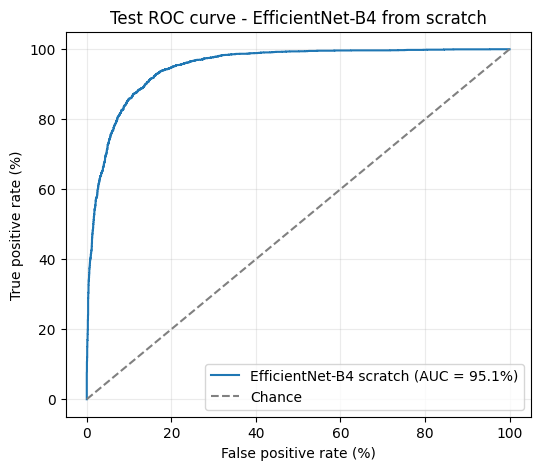

                                            Model  Accuracy  Precision  Recall   F1  ROC-AUC
                   EfficientNet-B4 (from scratch)      88.0       87.7    88.0 87.8     95.1
Custom SE-ResNet CNN + Transformer (from scratch)      87.1       87.0    86.7 86.9     94.2

Saved to /content/drive/MyDrive/ML-dataset/P2_results/efficientnet_b4_scratch
Send the printed table (or effb4_scratch_summary.json) back so the thesis paper can be updated.


In [9]:
# Cell 8: ROC curve + comparison with the main model, save everything to Drive
import json, pandas as pd
plt.figure(figsize=(6, 5)); plt.plot(fpr * 100, tpr * 100, label=f"EfficientNet-B4 scratch (AUC = {roc_auc*100:.1f}%)")
plt.plot([0, 100], [0, 100], "--", color="gray", label="Chance")
plt.xlabel("False positive rate (%)"); plt.ylabel("True positive rate (%)"); plt.title("Test ROC curve - EfficientNet-B4 from scratch")
plt.legend(loc="lower right"); plt.grid(alpha=0.25); plt.savefig(RESULTS_DIR / "effb4_scratch_test_roc.png", dpi=150); plt.show()

summary = {
    "model": "EfficientNet-B4 trained from scratch (weights=None, no pretrained weights)",
    "input": "224x224, batch 32, same augmentation and splits as the main model",
    "epochs_run": len(hist.history["loss"]), "best_epoch": best_epoch, "trainable_params": n_params,
    "best_val_auc": float(max(hist.history["val_auc"])),
    "test": {"accuracy": float(acc), "precision_fake": float(prec), "recall_fake": float(rec),
             "f1_fake": float(f1), "roc_auc": roc_auc, "confusion_matrix": matrix.tolist()},
}
json.dump(summary, open(RESULTS_DIR / "effb4_scratch_summary.json", "w"), indent=2)
open(RESULTS_DIR / "effb4_scratch_test_report.txt", "w").write(f"{summary}\n\n{report_text}")

table = pd.DataFrame([
    {"Model": "EfficientNet-B4 (from scratch)", "Accuracy": acc * 100, "Precision": prec * 100,
     "Recall": rec * 100, "F1": f1 * 100, "ROC-AUC": roc_auc * 100},
    {"Model": "Custom SE-ResNet CNN + Transformer (from scratch)", "Accuracy": 87.1, "Precision": 87.0,
     "Recall": 86.7, "F1": 86.9, "ROC-AUC": 94.2},
]).round(1)
print(table.to_string(index=False))
table.to_csv(RESULTS_DIR / "effb4_scratch_vs_main_model.csv", index=False)
print("\nSaved to", RESULTS_DIR)
print("Send the printed table (or effb4_scratch_summary.json) back so the thesis paper can be updated.")